In [1]:
%pip install -U "qiskit[visualization]" qiskit-ibm-runtime

Note: you may need to restart the kernel to use updated packages.


In [ ]:
from getpass import getpass
from qiskit_ibm_runtime import QiskitRuntimeService

api_key = getpass("Enter your IBM Quantum API key: ")
crn = input("Enter your IBM Quantum CRN: ").strip()

service = QiskitRuntimeService(
    channel="ibm_quantum_platform",
    token=api_key,
    instance=crn
)

print("Connected to IBM Quantum successfully.")

In [3]:
backend = service.least_busy(
    min_num_qubits=2,
    operational=True,
    simulator=False
)

print("Selected quantum computer:", backend.name)
print("Backend status:", backend.status().status_msg)

Selected quantum computer: ibm_kingston
Backend status: active


# Qiskit Fall Fest 2026
## Challenge 4: Quantum Correlation Switch

### Objective

To create two quantum circuits and compare their measurement correlations.

### Predictions

**Part A: Correlated outcomes**

The Bell-state circuit is expected to produce mostly 00 and 11. Both qubits should usually have the same measurement value.

**Part B: Opposite outcomes**

Adding an X gate to the second qubit is expected to produce mostly 01 and 10. The qubits should usually have opposite measurement values.

Both circuits will be executed for 100 shots on IBM Quantum hardware.

Part A: Correlated outcomes


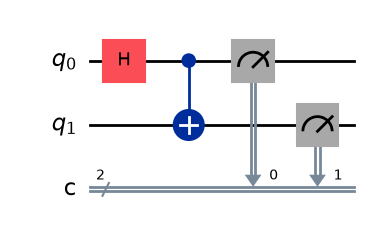

Part B: Opposite outcomes


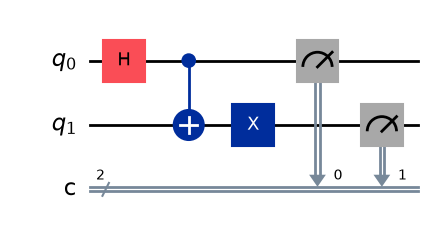

In [4]:
# CELL 5: Create the correlated and opposite-outcome circuits

from qiskit import QuantumCircuit
from IPython.display import display

# Part A: Correlated outcomes
circuit_a = QuantumCircuit(2, 2)
circuit_a.h(0)
circuit_a.cx(0, 1)
circuit_a.measure([0, 1], [0, 1])

# Part B: Opposite outcomes
circuit_b = QuantumCircuit(2, 2)
circuit_b.h(0)
circuit_b.cx(0, 1)
circuit_b.x(1)
circuit_b.measure([0, 1], [0, 1])

circuits = [circuit_a, circuit_b]

print("Part A: Correlated outcomes")
display(circuit_a.draw("mpl"))

print("Part B: Opposite outcomes")
display(circuit_b.draw("mpl"))

In [5]:
# CELL 6: Compile both circuits for the selected backend

from qiskit.transpiler import generate_preset_pass_manager

pass_manager = generate_preset_pass_manager(
    backend=backend,
    optimization_level=1
)

compiled_circuits = pass_manager.run(circuits)

print("Both circuits are ready for execution.")

Both circuits are ready for execution.


In [6]:
# CELL 7: Execute both circuits on IBM Quantum hardware

from qiskit_ibm_runtime import SamplerV2

sampler = SamplerV2(mode=backend)

job = sampler.run(
    compiled_circuits,
    shots=100
)

print("Job ID:", job.job_id())
print("Waiting for hardware results...")

result = job.result()

print("Execution completed successfully.")

C:\Users\SUSEELA\AppData\Local\Temp\ipykernel_5900\31978128.py:5: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Sampler` import will be updated to point to the client-side sampler in an upcoming release, with the legacy Sampler being available until the deprecation is completed.
  sampler = SamplerV2(mode=backend)


Job ID: db5sj02mb58s738aursg
Waiting for hardware results...
Execution completed successfully.


In [7]:
# CELL 8: Extract counts for both experiments

print("Available result fields:", result[0].data.keys())

counts_a = result[0].data.c.get_counts()
counts_b = result[1].data.c.get_counts()

print("Part A counts:", counts_a)
print("Part A total shots:", sum(counts_a.values()))

print()

print("Part B counts:", counts_b)
print("Part B total shots:", sum(counts_b.values()))

Available result fields: dict_keys(['c'])
Part A counts: {'01': 16, '11': 51, '00': 26, '10': 7}
Part A total shots: 100

Part B counts: {'01': 40, '10': 36, '11': 24}
Part B total shots: 100


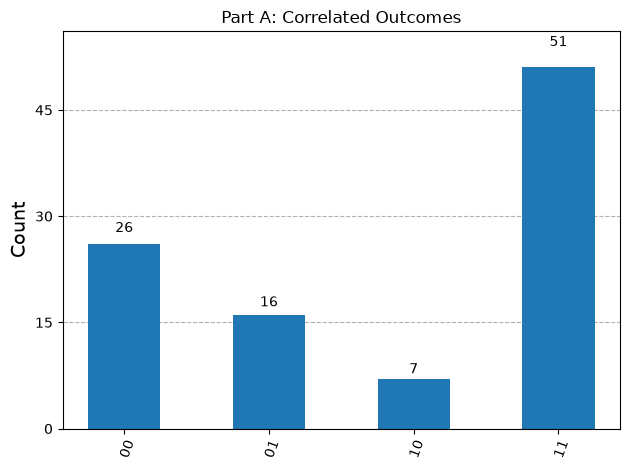

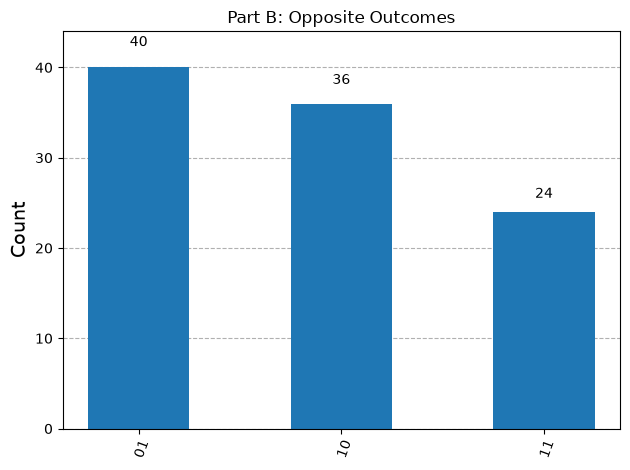

In [8]:
# CELL 9: Plot the measurement histograms

from qiskit.visualization import plot_histogram

display(plot_histogram(
    counts_a,
    title="Part A: Correlated Outcomes"
))

display(plot_histogram(
    counts_b,
    title="Part B: Opposite Outcomes"
))

In [9]:
# CELL 10: Compare predictions with actual results

import pandas as pd

comparison = pd.DataFrame([
    {
        "Part": "A",
        "Circuit": "Bell state",
        "Expected Outcomes": "00 and 11",
        "Actual Counts": str(counts_a),
        "Total Shots": sum(counts_a.values())
    },
    {
        "Part": "B",
        "Circuit": "Bell state + X gate",
        "Expected Outcomes": "01 and 10",
        "Actual Counts": str(counts_b),
        "Total Shots": sum(counts_b.values())
    }
])

display(comparison)

,Part,Circuit,Expected Outcomes,Actual Counts,Total Shots
0,A,Bell state,00 and 11,"{'01': 16, '11': 51, '00': 26, '10': 7}",100
1,B,Bell state + X gate,01 and 10,"{'01': 40, '10': 36, '11': 24}",100


## Observation and Conclusion

Part A used a Hadamard gate and a CNOT gate to create a Bell state. The dominant measurement outcomes were expected to be 00 and 11, showing that the two qubits usually produced the same value.

In Part B, an X gate was added to the second qubit. The expected outcomes changed to 01 and 10, showing that the qubits usually produced opposite values.

The results demonstrate that adding one quantum gate can switch the relationship between the measurement outcomes. Small differences from the expected results may occur because of noise and measurement errors on real quantum hardware.